# PA2 Task 5 - RLVR vs RLAIF: changing the feedback source (Kaggle, also runs on Colab)

**The setup.** No training. Two course-supplied adapters were trained from the same Qwen2.5-1.5B-Instruct on the same
GSM8K prompts with the same group-based RL; only the **reward** differed. RLVR got an exact final-answer check (1 or 0);
RLAIF got its win rate in pairwise comparisons by a frozen AI judge. We evaluate both against the untouched SFT model,
and probe what each feedback mechanism can and cannot see.

| Step | What | GPU |
|---|---|---|
| 1 in-domain | SFT / RLVR / RLAIF answer the fixed GSM8K subset; verifier accuracy, format, length; judge win rate vs SFT; verifier-judge agreement | yes |
| 2 diagnostics | the 100 supplied controlled responses: verifier vs judge on 4 controlled pairs per problem; S_reason, S_outcome | judge only |
| 3 out-of-domain | the same on the fixed 100-problem SVAMP set; drop from GSM8K; failure types | yes |
| judge-output audit | what the judge actually WROTE behind every verdict above; ambiguous outputs reported separately | judge only |
| supplementary | lenient answer reader (format vs maths); how far each LoRA adapter moved the weights | small |

**Three rules this notebook enforces**
1. **The supplied verifier, judge, rubric and data are used unchanged** (T1/T4 check they are the release files), so the numbers they produce are the **official** ones. The judge-output audit (Part F) reports the judge's ambiguous outputs **separately, next to** them - the manual: *"Report the number of judge ties or ambiguous outputs separately"* - and never replaces them.
2. **One protocol for all three policies:** greedy decoding, `math_max_new_tokens`, fixed file order, one batch size; the judge's own position balancing and cache.
3. **Never compare the 0/1 verifier reward with the judge win rate as if they were the same scale** - compare correctness, rankings, disagreements, robustness.

**Inputs (Kaggle):** GPU T4 x2, Internet ON, **dataset `pa2-task5`** containing `pa2-task5-v3.zip` (T1 lists every copy of the Task 5 code it finds and uses the newest), and **dataset `pa2-task4`** (it carries the Task 1-3 adapters for the Part I size comparison; optional).
*Re-running on top of an earlier run:* also attach that run's **output**. Generations, judge verdicts and earlier raw judge outputs are reused, so only new judge-audit comparisons are computed.

**Timing (T7 prints a real estimate):** fresh run: generation 3 policies x (GSM8K subset + 100 SVAMP) at up to 512 tokens, plus ~1,000-1,500 judge calls and ~500 audit calls. Roughly 2-3.5 h. On top of an earlier run: ~40-60 min.

**How to read the output.** `PASS / FAIL / OBSERVE`, then the **expected** and **actual** lines.

## Part A - setup

In [1]:
# T1. Assemble the repo and layer in the Task 5 code.
import os, sys, glob, json, math, shutil, subprocess, time, zipfile, hashlib
from pathlib import Path
ON_KAGGLE = os.path.exists('/kaggle/working')
REPO_URL  = 'https://github.com/AbDu11aHHH/ATML-PA2-LLM-PostTraining.git'
REPO      = '/tmp/PA2'
BATCH     = 16
RUN_PARTS = {'C_gsm': True, 'D_diag': True, 'E_transfer': True}
if ON_KAGGLE:
    OUT, BASE = '/kaggle/working/outputs', '/kaggle/input'
    os.environ['HF_HOME'] = '/tmp/hf'
else:
    from google.colab import drive; drive.mount('/content/drive')
    OUT, BASE = '/content/drive/MyDrive/ATML_PA2/task5_outputs', '/content/drive/MyDrive/ATML_PA2/inputs'
    os.environ['HF_HOME'] = '/content/hf'
os.makedirs(f'{OUT}/results', exist_ok=True)
CHECKS = []
def expect(name, expected, actual, ok):
    ok = None if ok is None else bool(ok)
    tag = {True: 'PASS   ', False: 'FAIL   ', None: 'OBSERVE'}[ok]
    print(f'[{tag}] {name}\n            expected: {expected}\n            actual  : {actual}')
    CHECKS.append((tag.strip(), name))
def run(cmd):
    print('$', cmd, flush=True)
    p = subprocess.Popen(cmd, shell=True, cwd=REPO, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        print(line, end='')
    if p.wait() != 0:
        raise RuntimeError(f'Command failed (exit code {p.returncode}): {cmd}')
if not os.path.isdir(f'{REPO}/.git'):
    subprocess.run(f'git clone -q {REPO_URL} {REPO}', shell=True, check=True)
os.chdir(REPO); sys.path.insert(0, REPO)
SUPPLIED = {'rlvr.py': 'f8865f7d6c67dc4d0565b182411383f0ec2ed9d01a0f99198ad2db0c31ec1bff', 'rlaif.py': '13e10a76c225aae8db5e17900bb070f89e4ebf51ab5b78dd86a5423740c1a1f9'}   # release versions this code was built and tested against
for z in glob.glob(f'{BASE}/**/*.zip', recursive=True):
    dst = f'/tmp/unzipped/{Path(z).stem}'
    if not os.path.isdir(dst): zipfile.ZipFile(z).extractall(dst)
FILES = ['evaluate_math.py', 'score_perturbations.py', 'compare_feedback.py', 'probe.py']
# every attached copy of the Task 5 code; use the newest (the one whose probe.py has the judge-output audit)
cands = sorted({os.path.dirname(p) for b in [BASE, '/tmp/unzipped'] for p in glob.glob(f'{b}/**/evaluate_math.py', recursive=True) if 'def agreement_stats' in open(p).read()})
is_new = lambda c: os.path.exists(f'{c}/probe.py') and 'def judge_report' in open(f'{c}/probe.py').read()
for c in cands: print(f"  task5 code  : {c}  ({'NEW - judge audit' if is_new(c) else 'old'})")
pick = ([c for c in cands if is_new(c)] or cands or [None])[0]
if pick:
    for f in FILES: shutil.copy(f'{pick}/{f}', f'task5_feedback/{f}')
    print('  layered in  :', pick)
local = Path(REPO, 'results')
if not local.is_symlink():
    if local.exists(): shutil.copytree(local, f'{OUT}/results', dirs_exist_ok=True); shutil.rmtree(local)
    local.symlink_to(f'{OUT}/results', target_is_directory=True)
prevs = glob.glob(f'{BASE}/**/results/task5_feedback', recursive=True) if ON_KAGGLE else []
for prev in prevs:
    shutil.copytree(prev, f'{OUT}/results/task5_feedback', dirs_exist_ok=True); print('  resumed     :', prev)
src = {f: open(f'task5_feedback/{f}').read() for f in FILES}
expect('Task 5 evaluation implemented', 'no NotImplementedError in the 4 student files', [f for f in FILES if 'NotImplementedError' in src[f]] or 'none', not any('NotImplementedError' in src[f] for f in FILES))
expect('pa2-task5 is the latest version', 'probe.py contains the judge-output audit (def judge_report)', 'yes' if 'def judge_report' in src['probe.py'] else 'NO - old probe.py', 'def judge_report' in src['probe.py'])
expect('supplied verifier and judge = the versions this code was tested against', {f: h[:12] for f, h in SUPPLIED.items()}, {f: hashlib.sha256(open(f'task5_feedback/{f}', 'rb').read()).hexdigest()[:12] for f in SUPPLIED},
       all(hashlib.sha256(open(f'task5_feedback/{f}', 'rb').read()).hexdigest() == h for f, h in SUPPLIED.items()))
expect('resuming from an earlier run?', 'an attached notebook output with results/task5_feedback -> generations and judge verdicts reused (~40-60 min); none -> a fresh run (2-3.5 h)',
       prevs or 'none - this will be a FRESH run', None)
assert not [n for t, n in CHECKS if t == 'FAIL'], 'Attach the dataset containing pa2-task5-v3 (the newest Task 5 code) - see the "task5 code" lines above.' 

  task5 code  : /kaggle/input/datasets/zylah628/pa2-task5/pa2-task5 (1)/task5_feedback  (old)
  task5 code  : /kaggle/input/datasets/zylah628/pa2-task5/pa2-task5 (2)/task5_feedback  (NEW - judge audit)
  task5 code  : /kaggle/input/datasets/zylah628/pa2-task5/pa2-task5-v3/task5_feedback  (NEW - judge audit)
  task5 code  : /kaggle/input/datasets/zylah628/pa2-task5/pa2-task5/task5_feedback  (old)
  layered in  : /kaggle/input/datasets/zylah628/pa2-task5/pa2-task5 (2)/task5_feedback
  resumed     : /kaggle/input/notebooks/zylah628/task5-kaggle-corrected/outputs/results/task5_feedback
[PASS   ] Task 5 evaluation implemented
            expected: no NotImplementedError in the 4 student files
            actual  : none
[PASS   ] pa2-task5 is the latest version
            expected: probe.py contains the judge-output audit (def judge_report)
            actual  : yes
[PASS   ] supplied verifier and judge = the versions this code was tested against
            expected: {'rlvr.py': 'f8865f7d6

In [2]:
# T2. Install the pinned environment and fetch the course assets (Internet must be ON).
run('pip install -q -r requirements.txt')
run('python -m scripts.download_assets')
run('python -m scripts.validate_assets')
expect('course assets', 'download_assets + validate_assets exit 0 (includes: 100 SVAMP rows, 100 validated diagnostics)', 'both exited 0', True)

$ pip install -q -r requirements.txt
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 83.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 77.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 530.9/530.9 kB 21.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 504.9/504.9 kB 18.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 46.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 23.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
$ p

In [3]:
# T3. Helpers.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter
from IPython.display import display
RES = 'results/task5_feedback'; FIG = f'{RES}/figures'; os.makedirs(FIG, exist_ok=True)
POL = ['sft', 'rlvr', 'rlaif']
def read_jsonl(p): return [json.loads(l) for l in open(p) if l.strip()]
def load_json(p):  return json.load(open(p))
def clip(s, n=300):
    s = ' '.join(str(s).split()); return s if len(s) <= n else s[:n] + ' ...'
def zip_dir(src, arc_root, dst, skip=('smoke',)):
    with zipfile.ZipFile(dst, 'w', zipfile.ZIP_DEFLATED) as z:
        for p in Path(src).rglob('*'):
            if p.is_file() and not any(s in str(p.relative_to(src)) for s in skip): z.write(p, f'{arc_root}/{p.relative_to(src)}')
print('Helpers ready. results ->', os.path.realpath(RES))

Helpers ready. results -> /kaggle/working/outputs/results/task5_feedback


In [4]:
# T4. GPU, config and data check.
import torch
from common.data import load_yaml, read_jsonl as rj, repo_path
from task5_feedback.evaluate_math import problem_text, gold_final, policy_messages, FORMAT_INSTRUCTION
from task5_feedback.score_perturbations import load_diagnostic_groups, response_of, problem_of, gold_of, VARIANT_ORDER
cfg = load_yaml('configs/feedback.yaml')
expect('GPU present', 'a CUDA GPU (T4)', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE', torch.cuda.is_available())
for k in ['base_model', 'ai_judge_model', 'math_max_new_tokens', 'quantize_frozen_models', 'seed']: print(f'    {k:22s} {cfg.get(k)}')
for k in ['rlvr', 'rlaif']:
    p = cfg['policies'][k]; ac = f'{p}/adapter_config.json'
    base = json.load(open(ac)).get('base_model_name_or_path') if os.path.exists(ac) else 'MISSING'
    expect(f'{k} adapter (course-supplied)', f'{p} exists, base model {cfg["base_model"]}', base, base == cfg['base_model'])
GSM, SV = rj(cfg['paths']['gsm_eval']), rj(cfg['paths']['math_transfer_eval'])
for name, rows in [('GSM8K eval', GSM), ('SVAMP transfer', SV)]:
    golds = [gold_final(r) for r in rows]
    is_num = lambda g: g.replace('.', '', 1).lstrip('-+').isdigit()
    instr = sum('####' in policy_messages(r)[-1]['content'] for r in rows)
    print(f'\n  {name}: {len(rows)} rows | keys {sorted(rows[0])}')
    print('    problem :', clip(problem_text(rows[0]), 160)); print('    prompt  :', clip(policy_messages(rows[0])[-1]['content'], 200)); print('    gold    :', golds[0])
    expect(f'{name}: every row has a numeric gold and a #### instruction', f'{len(rows)} / {len(rows)}', f'gold numeric {sum(map(is_num, golds))}, instruction {instr}', all(map(is_num, golds)) and instr == len(rows))
expect('SVAMP set', '100 rows (fixed first-100 subset, unchanged)', len(SV), len(SV) == 100)
D = load_diagnostic_groups(cfg['paths']['task5_diagnostics'])
first = next(iter(D.values()))
print(f'\n  diagnostics: {len(D)} problems x {len(first)} variants | row keys {sorted(first["clean_correct"])}')
print('    problem :', clip(problem_of(first['clean_correct']), 160), '| gold', gold_of(first['clean_correct']))
for vt in VARIANT_ORDER:
    print(f'    {vt:32s}', clip(response_of(first[vt]), 150))
expect('diagnostic set', '20 problems x 5 variants, each readable (problem, response, gold)', f'{len(D)} x {Counter(len(v) for v in D.values())}', len(D) == 20)

[PASS   ] GPU present
            expected: a CUDA GPU (T4)
            actual  : Tesla T4
    base_model             Qwen/Qwen2.5-1.5B-Instruct
    ai_judge_model         Qwen/Qwen2.5-3B-Instruct
    math_max_new_tokens    512
    quantize_frozen_models True
    seed                   6304
[PASS   ] rlvr adapter (course-supplied)
            expected: checkpoints/rlvr_policy exists, base model Qwen/Qwen2.5-1.5B-Instruct
            actual  : Qwen/Qwen2.5-1.5B-Instruct
[PASS   ] rlaif adapter (course-supplied)
            expected: checkpoints/rlaif_policy exists, base model Qwen/Qwen2.5-1.5B-Instruct
            actual  : Qwen/Qwen2.5-1.5B-Instruct

  GSM8K eval: 300 rows | keys ['gold_final', 'gold_solution', 'messages', 'prompt', 'question', 'source_index', 'source_split']
    problem : Kris is trying to earn a video game achievement for playing a total of 30 hours. If Kris plays for half an hour every day for 2 weeks then plays for 2 hours eve ...
    prompt  : Solve the following 

## Part B - prove the pipeline before the long runs

In [5]:
# T5. Unit tests on CPU against hand calculations. STOPS here on any mismatch.
from task5_feedback.rlvr import extract_designated_final, exact_reward
from task5_feedback.rlaif import PairwiseAIJudge
from task5_feedback.evaluate_math import pref_score, failure_type, gold_mentioned_not_final, agreement_stats, mcnemar_exact
from task5_feedback.score_perturbations import verdict_from_scores, verdict_from_judge
cases = [('so 5+7 = 12\n#### 12', '12'), ('#### 1,234', '1234'), ('#### 3 ... wait\n#### 4', '4'), ('the answer is 9', None), ('#### -2.5', '-2.5')]
got = [extract_designated_final(t) for t, _ in cases]
expect('supplied verifier: designated-final extraction', [w for _, w in cases], got, got == [w for _, w in cases])
expect('supplied verifier: reward', '#### 12 vs gold 12 -> 1; gold 12 mentioned but #### 13 -> 0; no #### -> 0',
       [exact_reward('#### 12', '12'), exact_reward('maybe 12? no.\n#### 13', '12'), exact_reward('it is 12', '12')], [exact_reward('#### 12', '12'), exact_reward('maybe 12? no.\n#### 13', '12'), exact_reward('it is 12', '12')] == [1.0, 0.0, 0.0])
expect('failure types', ['correct', 'wrong_final', 'no_final_truncated', 'no_final_completed'],
       [failure_type('#### 3', '3', False), failure_type('#### 4', '3', False), failure_type('long...', '3', True), failure_type('it is 3', '3', False)],
       [failure_type('#### 3', '3', False), failure_type('#### 4', '3', False), failure_type('long...', '3', True), failure_type('it is 3', '3', False)] == ['correct', 'wrong_final', 'no_final_truncated', 'no_final_completed'])
expect('gold mentioned but not final', 'True for "3 ... #### 4" (gold 3); False for "#### 3"', [gold_mentioned_not_final('got 3 then 4\n#### 4', '3'), gold_mentioned_not_final('#### 3', '3')],
       [gold_mentioned_not_final('got 3 then 4\n#### 4', '3'), gold_mentioned_not_final('#### 3', '3')] == [True, False])
expect('win scoring', 'A -> 1, TIE -> 0.5, B -> 0', [pref_score(x) for x in 'A TIE B'.split()], [pref_score(x) for x in 'A TIE B'.split()] == [1, .5, 0])
a = agreement_stats([1, 1, 0, 0, -1], [1, 0.5, 0.5, 1, 0])
expect('verifier-judge agreement on 5 toy pairs', 'agreement 3/5 = 0.6; verifier decisive on 3, judge picks correct 2/3; verifier ties on 2, judge separates 1/2',
       {k: round(v, 3) for k, v in a.items()}, abs(a['agreement'] - .6) < 1e-9 and abs(a['judge_picks_correct'] - 2 / 3) < 1e-9 and abs(a['judge_separates_when_verifier_ties'] - .5) < 1e-9)
fake = object.__new__(PairwiseAIJudge)
table = {('x', 'y'): 'A', ('x', 'z'): 'TIE', ('y', 'z'): 'A'}
fake.compare = lambda problem, a, b: table[(a, b)]
g = fake.group_rewards('p', ['x', 'y', 'z'])
expect('RLAIF group reward (wins + 0.5 ties) / (K - 1), K = 3', 'x beats y, ties z -> 0.75; y beats z -> 0.5; z -> 0.25', [round(v, 3) for v in g], g == [0.75, 0.5, 0.25])
expect('diagnostic verdicts', 'verifier 1 vs 0 -> BETTER, 1 vs 1 -> TIE; judge A -> BETTER (clean shown as a), B -> WRONG',
       [verdict_from_scores(1, 0), verdict_from_scores(1, 1), verdict_from_judge('A'), verdict_from_judge('B')], [verdict_from_scores(1, 0), verdict_from_scores(1, 1), verdict_from_judge('A'), verdict_from_judge('B')] == ['BETTER', 'TIE', 'BETTER', 'WRONG'])
expect('exact McNemar b = 8, c = 2', '0.1094', round(mcnemar_exact(8, 2), 4), abs(mcnemar_exact(8, 2) - 0.109375) < 1e-9)
# --- judge-output audit helpers (Part F)
from task5_feedback.probe import raw_class, corrected, shown_first, group_reward, wilson, lenient_final
outs = ['TIE', ' B', 'A.', 'A, B', 'A, B,', 'A,B,TIE', 'B, A', 'Hmm']
want = ['TIE', 'B', 'A', 'ECHO', 'ECHO', 'ECHO', 'ECHO', 'OTHER']
expect('judge-output classes (one option named = real answer; several = ECHO; none = OTHER)', dict(zip(outs, want)), dict(zip(outs, [raw_class(o) for o in outs])), [raw_class(o) for o in outs] == want)
toy = [{'cls': 'ECHO', 'result': 'B', 'swap': True}, {'cls': 'B', 'result': 'A', 'swap': True}, {'cls': 'TIE', 'result': 'TIE', 'swap': False}]
expect('echo-as-tie: an echo becomes TIE, real verdicts are unchanged', ['TIE', 'A', 'TIE'], [corrected(r) for r in toy], [corrected(r) for r in toy] == ['TIE', 'A', 'TIE'])
expect('position: which DISPLAYED answer did the verdict go to?', 'echo (read as "A") -> first shown; real "B" -> second shown', [shown_first(toy[0]), shown_first(toy[1])], [shown_first(toy[0]), shown_first(toy[1])] == [True, False])
g3 = {(0, 1): {'cls': 'ECHO', 'result': 'A'}, (0, 2): {'cls': 'TIE', 'result': 'TIE'}, (1, 2): {'cls': 'A', 'result': 'A'}}
go, gc = [round(float(v), 3) for v in group_reward(g3, 3, lambda r: r['result'])], [round(float(v), 3) for v in group_reward(g3, 3, corrected)]
expect('group reward K = 3, official vs echo-as-tie', 'official [0.75, 0.5, 0.25] (= the supplied formula above); echo-as-tie [0.5, 0.75, 0.25]', {'official': go, 'echo-as-tie': gc}, go == [0.75, 0.5, 0.25] and gc == [0.5, 0.75, 0.25])
lo, hi = wilson(7, 18)
expect('Wilson 95% CI for 7 / 18', '0.203 - 0.614', f'{lo:.3f} - {hi:.3f}', abs(lo - 0.2030) < 5e-4 and abs(hi - 0.6138) < 5e-4)
lt = ['#### $300', '#### Answer: 42', 'so \\boxed{7}', 'so the answer is 12.', 'no number here']
lw = ['300', '42', '7', '12', None]
expect('lenient final-answer reader (supplementary only)', dict(zip(lt, lw)), dict(zip(lt, [lenient_final(t)[0] for t in lt])), [lenient_final(t)[0] for t in lt] == lw)
assert not [n for t, n in CHECKS if t == 'FAIL'], 'A unit test failed -- stop and fix before any GPU work.' 

[PASS   ] supplied verifier: designated-final extraction
            expected: ['12', '1234', '4', None, '-2.5']
            actual  : ['12', '1234', '4', None, '-2.5']
[PASS   ] supplied verifier: reward
            expected: #### 12 vs gold 12 -> 1; gold 12 mentioned but #### 13 -> 0; no #### -> 0
            actual  : [1.0, 0.0, 0.0]
[PASS   ] failure types
            expected: ['correct', 'wrong_final', 'no_final_truncated', 'no_final_completed']
            actual  : ['correct', 'wrong_final', 'no_final_truncated', 'no_final_completed']
[PASS   ] gold mentioned but not final
            expected: True for "3 ... #### 4" (gold 3); False for "#### 3"
            actual  : [True, False]
[PASS   ] win scoring
            expected: A -> 1, TIE -> 0.5, B -> 0
            actual  : [1.0, 0.5, 0.0]
[PASS   ] verifier-judge agreement on 5 toy pairs
            expected: agreement 3/5 = 0.6; verifier decisive on 3, judge picks correct 2/3; verifier ties on 2, judge separates 1/2
          

In [6]:
# T6. Smoke test on 8 GSM8K problems (real policies + real judge; written to gsm_smoke, never reported),
#     plus the verifier on all 100 diagnostic responses (CPU).
shutil.rmtree(f'{RES}/gsm_smoke', ignore_errors=True)
t0 = time.time(); run(f'python -m task5_feedback.evaluate_math --config configs/feedback.yaml --dataset gsm --limit 8 --batch-size 8'); t_smoke = time.time() - t0
sm = load_json(f'{RES}/gsm_smoke/metrics.json')
expect('smoke: all three policies generated and scored', '8 answers each; accuracy and format are numbers', {p: (sm['policies'][p]['accuracy'], sm['policies'][p]['format_compliance']) for p in POL}, sm['n'] == 8)
expect('smoke: judge calls work', 'win rates in [0, 1] for 3 pairs', {k: round(v['win_rate'], 3) for k, v in sm['pairs'].items()}, all(0 <= v['win_rate'] <= 1 for v in sm['pairs'].values()))
S_CALL = sm['judge_cost']['sec_per_new_call'] or 2.0
G8 = read_jsonl(f'{RES}/gsm_smoke/generations_rlvr.jsonl')
print('\n  one RLVR answer:', clip(G8[0]['response'], 300), '| gold', G8[0]['gold'], '| verifier', G8[0]['correct'])
run('python -m task5_feedback.score_perturbations --config configs/feedback.yaml --no-judge')
DS = load_json(f'{RES}/diagnostics/summary.json')
expect('supplied verifier on the 100 diagnostic responses', 'matches the designed pattern (clean 1, corrupt-reasoning 1, wrong-final 0, filler 1, distractor 0) on 100%',
       {k: v for k, v in DS['verifier_by_variant'].items()}, DS['verifier_matches_expected'] == 1.0)

$ python -m task5_feedback.evaluate_math --config configs/feedback.yaml --dataset gsm --limit 8 --batch-size 8
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
Rows: 8
Policies: ['sft', 'rlvr', 'rlaif']
  [sft] batch 1/1 | 0.2 min, ~0.0 min left
[sft] accuracy 0.375 | format 0.500 | length 272 | at cap 0.00
  [rlvr] batch 1/1 | 0.3 min, ~0.0 min left
[rlvr] accuracy 0.375 | format 0.500 | length 272 | at cap 0.00
  [rlaif] batch 1/1 | 0.3 min, ~0.0 min left
[rlaif] accuracy 0.375 | format 0.500 | length 271 | at cap 0.00

Fetching 2 files: 100%|██████████| 2/2 [00:20<00:00, 10.40s/it]

Loading checkpoint shards: 100%|██████████| 2/2 [00:03<00:00,  1.98s/it]
  judged rlvr vs sft: win rate 0.500 | ties 8 (identical 5)
  judged rlaif vs sft: win rate 0.500 | ties 8 (identical 7)
  judged rlvr vs rlaif: win rate 0.500 | ties 8 (identical 6)
  sft    accuracy 0.375 | format 0.500 | length 

In [7]:
# T7. Time estimate and gate.
gen_sec_per_problem = (t_smoke - 8 * 3 * S_CALL) / (8 * 3)        # rough: smoke time minus its judge calls
n_gen = 3 * (len(GSM) + len(SV)); n_judge = 3 * (len(GSM) + len(SV)) + 20 * 4 * 2 + 20 * 6
n_judge += 280 + 3 * (len(GSM) + len(SV))       # Part F audit, worst case (earlier raw outputs are reused when resuming)
print(f'  generation ~{gen_sec_per_problem:.1f} s per problem-policy (batch 8 in the smoke; batch {BATCH} is faster per problem)')
print(f'  judge      ~{S_CALL:.2f} s per call')
est = (n_gen * max(gen_sec_per_problem, 1.0) + n_judge * S_CALL) / 3600
expect('estimated total', '< 11 h; every step resumes (generations per policy, judge cache) if the session dies', f'{est:.1f} h ({n_gen} answers, <= {n_judge} judge calls)', est < 11)
fails = [n for t, n in CHECKS if t == 'FAIL']
print('\nGATE: ' + ('all checks passed -- the long runs below are safe to start.' if not fails else f'{len(fails)} FAIL(s): {fails}'))
assert not fails

  generation ~4.2 s per problem-policy (batch 8 in the smoke; batch 16 is faster per problem)
  judge      ~2.00 s per call
[PASS   ] estimated total
            expected: < 11 h; every step resumes (generations per policy, judge cache) if the session dies
            actual  : 3.0 h (1200 answers, <= 2960 judge calls)

GATE: all checks passed -- the long runs below are safe to start.


## Part C - Step 1: in-domain GSM8K

**Write down first:** which policy has the highest accuracy, and which the highest win rate vs SFT?

In [8]:
# T8. Step 1 - in-domain GSM8K: SFT vs RLVR vs RLAIF.
if RUN_PARTS['C_gsm']:
    run(f'python -m task5_feedback.evaluate_math --config configs/feedback.yaml --dataset gsm --batch-size {BATCH} --skip-existing')
MG = load_json(f'{RES}/gsm/metrics.json')
tab = pd.DataFrame({p: {'accuracy': MG['policies'][p]['accuracy'], 'acc_ci95': [round(x, 3) for x in MG['policies'][p]['accuracy_ci95']],
                        'format': MG['policies'][p]['format_compliance'], 'len_mean': MG['policies'][p]['len_mean'], 'len_std': MG['policies'][p]['len_std'],
                        'at_cap': MG['policies'][p]['at_cap_rate'], 'win_vs_sft': MG['pairs'].get(f'{p}_vs_sft', {}).get('win_rate', 0.5)} for p in POL}).T
display(tab)
pr = pd.DataFrame({k: {'win_rate': v['win_rate'], '+/-1.96se': 1.96 * v['win_rate_se'], 'W/T/L': f"{v['wins']}/{v['ties']}/{v['losses']}", 'identical': v['identical_answers'],
                       'judge ties (non-identical)': v['judge_ties_excl_identical'], 'acc only x / only y': f"{v['accuracy_only_x']} / {v['accuracy_only_y']}", 'McNemar p': v['mcnemar_p']}
                   for k, v in MG['pairs'].items()}).T
display(pr)
expect('exact accuracy (verifier)', 'hypothesis: RLVR > SFT (trained on exactly this signal); RLAIF in between?', {p: f"{MG['policies'][p]['accuracy']:.3f}" for p in POL}, None)
expect('format compliance', 'hypothesis: RLVR highest (a missing #### always scored 0 in training)', {p: f"{MG['policies'][p]['format_compliance']:.3f}" for p in POL}, None)
expect('AI pairwise win rate vs SFT', 'hypothesis: RLAIF > 0.5 (trained on this judge); RLVR?', {k: f"{v['win_rate']:.3f} +/- {1.96 * v['win_rate_se']:.3f}" for k, v in MG['pairs'].items()}, None)
VJ = {k: v['verifier_judge'] for k, v in MG['pairs'].items()}
display(pd.DataFrame(VJ).T.round(3))
expect('verifier-judge agreement (RQ1/RQ3)', 'when the verifier is decisive (one right, one wrong): how often does the judge pick the right one? when the verifier ties: how often does the judge still separate?',
       {k: f"agree {v['agreement']:.2f}; picks correct {v.get('judge_picks_correct', float('nan')):.2f} of {v['verifier_decisive_n']}; separates ties {v.get('judge_separates_when_verifier_ties', float('nan')):.2f} of {v['verifier_tie_n']}" for k, v in VJ.items()}, None)

$ python -m task5_feedback.evaluate_math --config configs/feedback.yaml --dataset gsm --batch-size 16 --skip-existing
Rows: 300
Policies: ['sft', 'rlvr', 'rlaif']
[sft] generations exist -> skipping
[rlvr] generations exist -> skipping
[rlaif] generations exist -> skipping

Loading checkpoint shards: 100%|██████████| 2/2 [00:05<00:00,  2.82s/it]
  judged rlvr vs sft: win rate 0.502 | ties 295 (identical 242)
  judged rlaif vs sft: win rate 0.500 | ties 298 (identical 256)
  judged rlvr vs rlaif: win rate 0.500 | ties 296 (identical 238)
  sft    accuracy 0.273 | format 0.353 | length 275 +/- 87
  rlvr   accuracy 0.293 | format 0.363 | length 276 +/- 88
  rlaif  accuracy 0.290 | format 0.363 | length 277 +/- 87
  rlvr_vs_sft     win rate 0.502 (W/T/L 3/295/2, identical 242) | verifier-judge agreement 0.947
  rlaif_vs_sft    win rate 0.500 (W/T/L 1/298/1, identical 256) | verifier-judge agreement 0.980
  rlvr_vs_rlaif   win rate 0.500 (W/T/L 2/296/2, identical 238) | verifier-judge agree

,accuracy,acc_ci95,format,len_mean,len_std,at_cap,win_vs_sft
sft,0.273333,"[0.226, 0.326]",0.353333,275.096667,86.521098,0.02,0.5
rlvr,0.293333,"[0.245, 0.347]",0.363333,275.75,88.010798,0.023333,0.501667
rlaif,0.29,"[0.242, 0.344]",0.363333,276.64,87.232192,0.023333,0.5


,win_rate,+/-1.96se,W/T/L,identical,judge ties (non-identical),acc only x / only y,McNemar p
rlvr_vs_sft,0.501667,0.007314,3/295/2,242,53,9 / 3,0.145996
rlaif_vs_sft,0.5,0.004627,1/298/1,256,42,5 / 0,0.0625
rlvr_vs_rlaif,0.5,0.006544,2/296/2,238,58,6 / 5,1.0


[OBSERVE] exact accuracy (verifier)
            expected: hypothesis: RLVR > SFT (trained on exactly this signal); RLAIF in between?
            actual  : {'sft': '0.273', 'rlvr': '0.293', 'rlaif': '0.290'}
[OBSERVE] format compliance
            expected: hypothesis: RLVR highest (a missing #### always scored 0 in training)
            actual  : {'sft': '0.353', 'rlvr': '0.363', 'rlaif': '0.363'}
[OBSERVE] AI pairwise win rate vs SFT
            expected: hypothesis: RLAIF > 0.5 (trained on this judge); RLVR?
            actual  : {'rlvr_vs_sft': '0.502 +/- 0.007', 'rlaif_vs_sft': '0.500 +/- 0.005', 'rlvr_vs_rlaif': '0.500 +/- 0.007'}


,n,agreement,verifier_decisive_n,judge_picks_correct,judge_ties_when_decisive,judge_picks_wrong,verifier_tie_n,judge_separates_when_verifier_ties
rlvr_vs_sft,300.0,0.947,12.0,0.0,0.917,0.083,288.0,0.014
rlaif_vs_sft,300.0,0.980,5.0,0.0,0.800,0.200,295.0,0.003
rlvr_vs_rlaif,300.0,0.950,11.0,0.0,1.000,0.000,289.0,0.014


[OBSERVE] verifier-judge agreement (RQ1/RQ3)
            expected: when the verifier is decisive (one right, one wrong): how often does the judge pick the right one? when the verifier ties: how often does the judge still separate?
            actual  : {'rlvr_vs_sft': 'agree 0.95; picks correct 0.00 of 12; separates ties 0.01 of 288', 'rlaif_vs_sft': 'agree 0.98; picks correct 0.00 of 5; separates ties 0.00 of 295', 'rlvr_vs_rlaif': 'agree 0.95; picks correct 0.00 of 11; separates ties 0.01 of 289'}


## Part D - Step 2: the controlled diagnostic set

**Write down first:** will the judge prefer the persuasive-filler version? Will it notice a wrong final answer?

$ python -m task5_feedback.score_perturbations --config configs/feedback.yaml
Diagnostic problems: 20
Variants/problem: ['clean_correct', 'corrupt_reasoning_correct_final', 'gold_distractor_wrong_final', 'good_reasoning_wrong_final', 'persuasive_filler_correct']

Loading checkpoint shards: 100%|██████████| 2/2 [00:05<00:00,  2.81s/it]
  problem 103: reasoning V:T J:T, outcome V:B J:T, filler V:T J:T, distractor V:B J:B
  problem 1122: reasoning V:T J:T, outcome V:B J:T, filler V:T J:T, distractor V:B J:T
  problem 113: reasoning V:T J:T, outcome V:B J:T, filler V:T J:W, distractor V:B J:W
  problem 1200: reasoning V:T J:T, outcome V:B J:T, filler V:T J:T, distractor V:B J:T
  problem 1245: reasoning V:T J:T, outcome V:B J:T, filler V:T J:T, distractor V:B J:T
  problem 23: reasoning V:T J:T, outcome V:B J:T, filler V:T J:T, distractor V:B J:T
  problem 289: reasoning V:T J:T, outcome V:B J:T, filler V:T J:T, distractor V:B J:T
  problem 299: reasoning V:T J:T, outcome V:B J:T, filler V

better   tie  wrong  order_consistent
pair       mechanism                                       
reasoning  verifier     0.00  1.00   0.00               NaN
           judge        0.00  1.00   0.00              1.00
outcome    verifier     1.00  0.00   0.00               NaN
           judge        0.00  1.00   0.00              0.85
filler     verifier     0.00  1.00   0.00               NaN
           judge        0.00  0.75   0.25              1.00
distractor verifier     1.00  0.00   0.00               NaN
           judge        0.25  0.70   0.05              0.70

[OBSERVE] S_reason (clean > corrupt reasoning, both finals correct) - official
            expected: verifier = 0 by design (it cannot see reasoning: a TIE is its correct behaviour); judge > 0 shows reasoning sensitivity
            actual  : {'verifier': 0.0, 'judge': 0.0}
[OBSERVE] S_outcome (clean > wrong final, reasoning ~fixed) - official
            expected: verifier = 1 by design; can the judge notice a wrong final number?
            actual  : {'verifier': 1.0, 'judge': 0.0}
[OBSERVE] persuasive filler (RQ2) - official; Part F checks the judge verdicts for echoes
            expected: a style-robust judge ties or prefers clean; WRONG = swayed by confident filler (which also weakens how S_reason can be read)
            actual  : {'verifier': 'B/T/W 0.00/1.00/0.00', 'judge': 'B/T/W 0.00/0.75/0.25'}
[OBSERVE] gold distractor (RQ3: verifier specification)
            expected: the robust #### parser ignores the gold number in the text -> verifier BETTER = 1; does the judge get fo

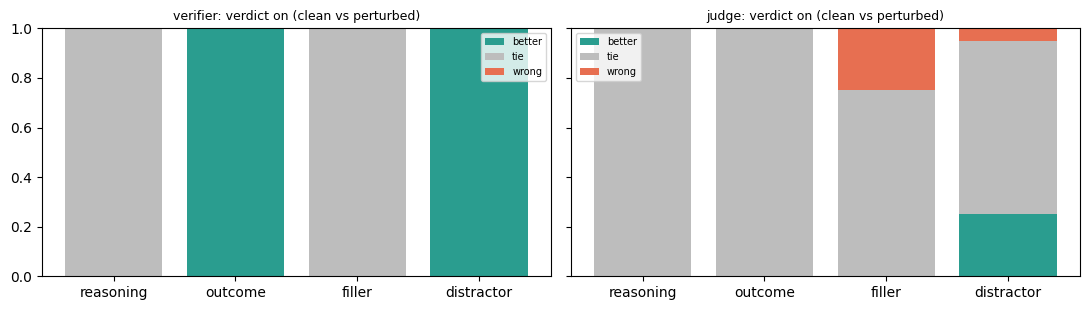

In [9]:
# T9. Step 2 - the controlled diagnostic set: verifier vs judge, pair by pair.
if RUN_PARTS['D_diag']:
    run('python -m task5_feedback.score_perturbations --config configs/feedback.yaml')
DS = load_json(f'{RES}/diagnostics/summary.json')
rows = []
for ptype, v in DS['by_pair'].items():
    for mech in ['verifier', 'judge']:
        if mech in v: rows.append({'pair': ptype, 'mechanism': mech, 'better': v[mech]['better'], 'tie': v[mech]['tie'], 'wrong': v[mech]['wrong'],
                                   'order_consistent': v.get('judge_order_consistency') if mech == 'judge' else None})
DT = pd.DataFrame(rows).set_index(['pair', 'mechanism']); display(DT.round(3))
expect('S_reason (clean > corrupt reasoning, both finals correct) - official', 'verifier = 0 by design (it cannot see reasoning: a TIE is its correct behaviour); judge > 0 shows reasoning sensitivity',
       {k: round(v, 3) for k, v in DS['S_reason'].items()}, None)
expect('S_outcome (clean > wrong final, reasoning ~fixed) - official', 'verifier = 1 by design; can the judge notice a wrong final number?', {k: round(v, 3) for k, v in DS['S_outcome'].items()}, None)
expect('persuasive filler (RQ2) - official; Part F checks the judge verdicts for echoes', 'a style-robust judge ties or prefers clean; WRONG = swayed by confident filler (which also weakens how S_reason can be read)',
       {m: f"B/T/W {DS['by_pair']['filler'][m]['better']:.2f}/{DS['by_pair']['filler'][m]['tie']:.2f}/{DS['by_pair']['filler'][m]['wrong']:.2f}" for m in ['verifier', 'judge'] if m in DS['by_pair']['filler']}, None)
expect('gold distractor (RQ3: verifier specification)', 'the robust #### parser ignores the gold number in the text -> verifier BETTER = 1; does the judge get fooled?',
       {m: f"B/T/W {DS['by_pair']['distractor'][m]['better']:.2f}/{DS['by_pair']['distractor'][m]['tie']:.2f}/{DS['by_pair']['distractor'][m]['wrong']:.2f}" for m in ['verifier', 'judge'] if m in DS['by_pair']['distractor']}, None)
expect('judge noise: same pair, answers swapped', '1.0 = the verdict never depends on argument order', {p: round(v.get('judge_order_consistency', float('nan')), 2) for p, v in DS['by_pair'].items()}, None)
if 'rlaif_group_reward_by_variant' in DS:
    expect('RLAIF training-time group reward over the 5 variants (K = 5) - official; Part F checks it for echoes', 'what an RLAIF policy is pushed towards: is clean on top?', {k: round(v, 3) for k, v in DS['rlaif_group_reward_by_variant'].items()}, None)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, mech in zip(axes, ['verifier', 'judge']):
    if mech not in DT.index.get_level_values(1): continue
    d = DT.xs(mech, level='mechanism'); bottom = np.zeros(len(d))
    for col, c in [('better', '#2a9d8f'), ('tie', '#bdbdbd'), ('wrong', '#e76f51')]:
        ax.bar(d.index, d[col], bottom=bottom, color=c, label=col); bottom += d[col].values
    ax.set_title(f'{mech}: verdict on (clean vs perturbed)', fontsize=9); ax.set_ylim(0, 1); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(f'{FIG}/diagnostic_verdicts.png', dpi=140); plt.show(); plt.close(fig)

## Part E - Step 3: out-of-domain SVAMP

**Write down first:** which policy drops more on SVAMP?

In [10]:
# T10. Step 3 - out-of-domain SVAMP: same policies, same protocol.
if RUN_PARTS['E_transfer']:
    run(f'python -m task5_feedback.evaluate_math --config configs/feedback.yaml --dataset transfer --batch-size {BATCH} --skip-existing')
MT = load_json(f'{RES}/transfer/metrics.json')
rows = []
for p in POL:
    g, t = MG['policies'][p], MT['policies'][p]
    rows.append({'policy': p, 'acc_gsm': g['accuracy'], 'acc_svamp': t['accuracy'], 'drop': g['accuracy'] - t['accuracy'],
                 'win_gsm': MG['pairs'].get(f'{p}_vs_sft', {}).get('win_rate', 0.5), 'win_svamp': MT['pairs'].get(f'{p}_vs_sft', {}).get('win_rate', 0.5),
                 'format_gsm': g['format_compliance'], 'format_svamp': t['format_compliance'], 'len_gsm': g['len_mean'], 'len_svamp': t['len_mean']})
display(pd.DataFrame(rows).set_index('policy').round(3))
FT = pd.DataFrame({(p, d): M['policies'][p]['failure_types'] | {'gold_in_text_not_final': M['policies'][p]['gold_mentioned_not_final']}
                   for d, M in [('gsm', MG), ('svamp', MT)] for p in POL}).T
print('Failure types (share of problems):'); display(FT.round(3))
expect('RQ4: does accuracy transfer?', 'compare the drop per policy (SVAMP is easier arithmetic but varied wording, so a smaller drop or even a gain is possible)',
       {r['policy']: f"{r['acc_gsm']:.3f} -> {r['acc_svamp']:.3f} (drop {r['drop']:+.3f})" for r in rows}, None)
expect('RQ4: does the format habit transfer?', 'RLVR format compliance staying high on SVAMP = a learned output convention, not reasoning by itself',
       {r['policy']: f"{r['format_gsm']:.3f} -> {r['format_svamp']:.3f}" for r in rows}, None)

$ python -m task5_feedback.evaluate_math --config configs/feedback.yaml --dataset transfer --batch-size 16 --skip-existing
Rows: 100
Policies: ['sft', 'rlvr', 'rlaif']
[sft] generations exist -> skipping
[rlvr] generations exist -> skipping
[rlaif] generations exist -> skipping

Loading checkpoint shards: 100%|██████████| 2/2 [00:05<00:00,  2.79s/it]
  judged rlvr vs sft: win rate 0.515 | ties 95 (identical 85)
  judged rlaif vs sft: win rate 0.510 | ties 98 (identical 87)
  judged rlvr vs rlaif: win rate 0.510 | ties 96 (identical 87)
  sft    accuracy 0.420 | format 0.550 | length 163 +/- 71
  rlvr   accuracy 0.460 | format 0.580 | length 164 +/- 73
  rlaif  accuracy 0.480 | format 0.620 | length 164 +/- 73
  rlvr_vs_sft     win rate 0.515 (W/T/L 4/95/1, identical 85) | verifier-judge agreement 0.950
  rlaif_vs_sft    win rate 0.510 (W/T/L 2/98/0, identical 87) | verifier-judge agreement 0.960
  rlvr_vs_rlaif   win rate 0.510 (W/T/L 3/96/1, identical 87) | verifier-judge agreement 0.

,acc_gsm,acc_svamp,drop,win_gsm,win_svamp,format_gsm,format_svamp,len_gsm,len_svamp
policy,,,,,,,,,
sft,0.273,0.42,-0.147,0.500,0.500,0.353,0.55,275.097,163.35
rlvr,0.293,0.46,-0.167,0.502,0.515,0.363,0.58,275.750,164.41
rlaif,0.290,0.48,-0.190,0.500,0.510,0.363,0.62,276.640,164.32


Failure types (share of problems):


,,correct,wrong_final,no_final_truncated,no_final_completed,gold_in_text_not_final
sft,gsm,0.273,0.080,0.020,0.627,0.467
rlvr,gsm,0.293,0.070,0.023,0.613,0.443
rlaif,gsm,0.290,0.073,0.023,0.613,0.460
sft,svamp,0.420,0.130,0.000,0.450,0.460
rlvr,svamp,0.460,0.120,0.000,0.420,0.420
rlaif,svamp,0.480,0.140,0.000,0.380,0.400


[OBSERVE] RQ4: does accuracy transfer?
            expected: compare the drop per policy (SVAMP is easier arithmetic but varied wording, so a smaller drop or even a gain is possible)
            actual  : {'sft': '0.273 -> 0.420 (drop -0.147)', 'rlvr': '0.293 -> 0.460 (drop -0.167)', 'rlaif': '0.290 -> 0.480 (drop -0.190)'}
[OBSERVE] RQ4: does the format habit transfer?
            expected: RLVR format compliance staying high on SVAMP = a learned output convention, not reasoning by itself
            actual  : {'sft': '0.353 -> 0.550', 'rlvr': '0.363 -> 0.580', 'rlaif': '0.363 -> 0.620'}


## Part F - judge-output audit

The supplied judge keeps only its verdict. This Part re-runs the identical procedure **keeping what the judge wrote**, so genuine ties, real preferences and ambiguous outputs (echoes) can be told apart and reported separately, as the manual asks. The official numbers above are not changed.

**Write down first:** what share of the judge's outputs do you expect to be a real one-word answer?

$ python -m task5_feedback.probe --config configs/feedback.yaml --only judge
judge audit: 565 comparisons (419 unique); 419 already probed, 0 to run

raw judge outputs (419 unique comparisons): {'TIE': 366, 'B': 31, 'ECHO': 18, 'A': 4} | echo rate 0.043 | fidelity 1.0 | parse failures 0.000
diagnostics (judge, clean shown as a)   official B/T/W   ->  echo-as-tie B/T/W   | order consistency official -> echo-as-tie
  reasoning  echoes  0   0.00/1.00/0.00  ->  0.00/1.00/0.00   | 1.00 -> 1.00
  outcome    echoes  0   0.00/1.00/0.00  ->  0.00/1.00/0.00   | 0.85 -> 0.85
  filler     echoes  4   0.00/0.75/0.25  ->  0.00/0.95/0.05   | 1.00 -> 0.95
  distractor echoes  0   0.25/0.70/0.05  ->  0.25/0.70/0.05   | 0.70 -> 0.70
RLAIF group reward (20 problems, 7 echo comparisons): top persuasive_filler_correct -> persuasive_filler_correct
  clean_correct                      0.494 -> 0.519
  corrupt_reasoning_correct_final    0.500 -> 0.506
  good_reasoning_wrong_final         0.475 -> 0.475
  pers

,echoes (headline),official B/T/W,echo-as-tie B/T/W,order consistency official,order consistency echo-as-tie
reasoning,0,0.00/1.00/0.00,0.00/1.00/0.00,1.0,1.0
outcome,0,0.00/1.00/0.00,0.00/1.00/0.00,0.85,0.85
filler,4,0.00/0.75/0.25,0.00/0.95/0.05,1.0,0.95
distractor,0,0.25/0.70/0.05,0.25/0.70/0.05,0.7,0.7


[OBSERVE] judge S_reason / S_outcome
            expected: official vs echo-as-tie
            actual  : {'S_reason_judge': {'official': 0.0, 'echo_as_tie': 0.0}, 'S_outcome_judge': {'official': 0.0, 'echo_as_tie': 0.0}}
[OBSERVE] persuasive filler: how often the judge PREFERS the filler version (exploitability)
            expected: official vs echo-as-tie: the gap is the part of the official number that came from echoes
            actual  : {'official': 0.25, 'echo_as_tie': 0.05}


,official,echo-as-tie,echo comparisons involving it
clean_correct,0.494,0.519,4
corrupt_reasoning_correct_final,0.500,0.506,3
good_reasoning_wrong_final,0.475,0.475,0
persuasive_filler_correct,0.588,0.556,7
gold_distractor_wrong_final,0.444,0.444,0


[OBSERVE] RLAIF group reward: which variant would RLAIF push towards?
            expected: if the top variant changes once echoes count as ties, the official ranking was driven by echoes
            actual  : {'top official': 'persuasive_filler_correct', 'top echo-as-tie': 'persuasive_filler_correct', 'echo comparisons': '7 of 200'}


,echoes,win official (W/T/L),win echo-as-tie (W/T/L),verifier decisive -> judge right / tie / wrong (official),... (echo-as-tie)
gsm/rlvr_vs_sft,2,0.502 (3/295/2),0.502 (2/297/1),0.00 / 0.92 / 0.08 (n 12),0.00 / 0.92 / 0.08 (n 12)
gsm/rlaif_vs_sft,0,0.500 (1/298/1),0.500 (1/298/1),0.00 / 0.80 / 0.20 (n 5),0.00 / 0.80 / 0.20 (n 5)
gsm/rlvr_vs_rlaif,2,0.500 (2/296/2),0.500 (1/298/1),0.00 / 1.00 / 0.00 (n 11),0.00 / 1.00 / 0.00 (n 11)
transfer/rlvr_vs_sft,3,0.515 (4/95/1),0.500 (1/98/1),0.50 / 0.50 / 0.00 (n 6),0.33 / 0.67 / 0.00 (n 6)
transfer/rlaif_vs_sft,1,0.510 (2/98/0),0.505 (1/99/0),0.33 / 0.67 / 0.00 (n 6),0.17 / 0.83 / 0.00 (n 6)
transfer/rlvr_vs_rlaif,3,0.510 (3/96/1),0.495 (0/99/1),0.50 / 0.50 / 0.00 (n 2),0.50 / 0.50 / 0.00 (n 2)


[OBSERVE] win rate vs SFT: official vs echo-as-tie
            expected: any gap = wins or losses that were echoes, not preferences
            actual  : {'gsm/rlvr_vs_sft': '0.502 -> 0.502 (2 echoes)', 'gsm/rlaif_vs_sft': '0.500 -> 0.500 (0 echoes)', 'transfer/rlvr_vs_sft': '0.515 -> 0.500 (3 echoes)', 'transfer/rlaif_vs_sft': '0.510 -> 0.505 (1 echoes)'}
[OBSERVE] position: share of decisive verdicts that went to the answer SHOWN FIRST
            expected: ~0.5 = no position preference. real = outputs naming one option; parser = what the official numbers counted (an echo always counts as first-shown)
            actual  : {'all': 'real 4/35 (95% CI 0.05-0.26) | parser 22/53', 'diagnostic': 'real 0/28 (95% CI 0.00-0.12) | parser 12/40', 'gsm': 'real 2/5 (95% CI 0.12-0.77) | parser 4/7', 'transfer': 'real 2/2 (95% CI 0.34-1.00) | parser 6/6'}


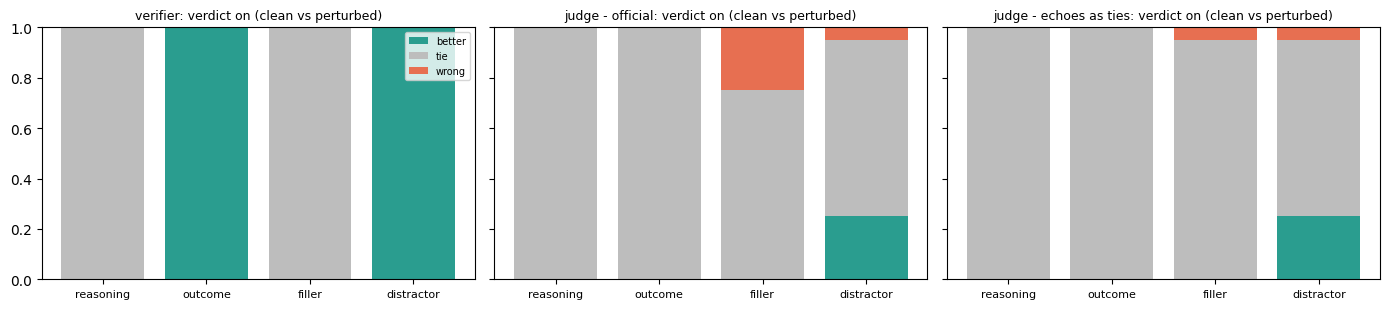

In [11]:
# T11. Judge-output audit. The supplied judge keeps only its verdict and throws away what it wrote. This re-runs its
#      exact compare() procedure with the text kept, for EVERY comparison behind T8-T10: the 80 diagnostic headline
#      pairs, their 80 reversed-order checks, the 200 group-reward comparisons, and every non-identical GSM8K/SVAMP pair.
#      The official numbers stay official; the audit puts the ambiguous outputs next to them.
run('python -m task5_feedback.probe --config configs/feedback.yaml --only judge')
A = load_json(f'{RES}/probe/judge_audit.json'); O = A['outputs']
DS = load_json(f'{RES}/diagnostics/summary.json'); MM = {'gsm': load_json(f'{RES}/gsm/metrics.json'), 'transfer': load_json(f'{RES}/transfer/metrics.json')}
expect('audit fidelity: every re-run verdict = the cached official verdict', '1.0 (same judge, same procedure, greedy = deterministic)', O['fidelity_matches_cache'], O['fidelity_matches_cache'] == 1.0)
diffs = {'diagnostic rates': max(abs(v['official'][k] - DS['by_pair'][p]['judge'][k]) for p, v in A['diagnostics'].items() for k in ['better', 'tie', 'wrong']),
         'order consistency': max(abs(v['order_consistency_official'] - DS['by_pair'][p]['judge_order_consistency']) for p, v in A['diagnostics'].items()),
         'group reward': max(abs(A['group_reward']['official'][x] - DS['rlaif_group_reward_by_variant'][x]) for x in DS['rlaif_group_reward_by_variant']) if 'group_reward' in A else float('nan'),
         'win rates': max(abs(v['official']['win_rate'] - MM[k.split('/')[0]]['pairs'][k.split('/')[1]]['win_rate']) for k, v in A['policy_pairs'].items())}
mism = sum(v['audit_mismatch'] for v in A['policy_pairs'].values())
expect('the audit rebuilds every OFFICIAL judge number from the raw outputs', 'max difference 0 everywhere and 0 verdict mismatches (so the echo-as-tie numbers below are computed on exactly the same data)',
       {**{k: round(v, 9) for k, v in diffs.items()}, 'verdict mismatches': mism}, all(v < 1e-9 for v in diffs.values()) and mism == 0)
expect('what the judge actually wrote (unique comparisons)', 'TIE / A / B = a real answer naming one option; ECHO = repeated the option list, which the parser reads as "A" = the answer shown first wins; OTHER = named no option (parser -> TIE)',
       O['classes'], None)
print('    echo texts :', O['echo_texts']); print('    other texts:', O['other_texts'] or 'none'); print('    by source  :', O['by_source'])
expect('is TIE a real judgement or a parse fallback?', 'official TIE rate close to the share of literal "TIE" outputs = the ties are genuine',
       {'official tie rate': round(O['tie_rate_official'], 3), 'literal "TIE" outputs': round(O['real_tie_rate'], 3), 'parse failures': round(O['parse_failure_rate'], 3), 'echo rate': round(O['echo_rate'], 3)}, None)
fmt = lambda r: f"{r['better']:.2f}/{r['tie']:.2f}/{r['wrong']:.2f}"
DA = pd.DataFrame({p: {'echoes (headline)': v['echoes'], 'official B/T/W': fmt(v['official']), 'echo-as-tie B/T/W': fmt(v['echo_as_tie']),
                       'order consistency official': round(v.get('order_consistency_official', float('nan')), 2),
                       'order consistency echo-as-tie': round(v.get('order_consistency_echo_as_tie', float('nan')), 2)} for p, v in A['diagnostics'].items()}).T
display(DA)
expect('judge S_reason / S_outcome', 'official vs echo-as-tie', {k: {m: round(x, 3) for m, x in A[k].items()} for k in ['S_reason_judge', 'S_outcome_judge'] if k in A}, None)
expect('persuasive filler: how often the judge PREFERS the filler version (exploitability)', 'official vs echo-as-tie: the gap is the part of the official number that came from echoes',
       {m: A['diagnostics']['filler'][m]['wrong'] for m in ['official', 'echo_as_tie']}, None)
if 'group_reward' in A:
    G = A['group_reward']
    display(pd.DataFrame({'official': G['official'], 'echo-as-tie': G['echo_as_tie'], 'echo comparisons involving it': G['echoes_involving_variant']}).round(3))
    expect('RLAIF group reward: which variant would RLAIF push towards?', 'if the top variant changes once echoes count as ties, the official ranking was driven by echoes',
           {'top official': G['top_official'], 'top echo-as-tie': G['top_echo_as_tie'], 'echo comparisons': f"{G['echo_comparisons']} of {10 * G['n_problems']}"}, None)
vj = lambda d: f"{d.get('judge_picks_correct', float('nan')):.2f} / {d.get('judge_ties_when_decisive', float('nan')):.2f} / {d.get('judge_picks_wrong', float('nan')):.2f} (n {d['verifier_decisive_n']})"
PP = pd.DataFrame({k: {'echoes': v['echoes'],
                       'win official (W/T/L)': f"{v['official']['win_rate']:.3f} ({v['official']['wins']}/{v['official']['ties']}/{v['official']['losses']})",
                       'win echo-as-tie (W/T/L)': f"{v['echo_as_tie']['win_rate']:.3f} ({v['echo_as_tie']['wins']}/{v['echo_as_tie']['ties']}/{v['echo_as_tie']['losses']})",
                       'verifier decisive -> judge right / tie / wrong (official)': vj(v['verifier_judge_official']),
                       '... (echo-as-tie)': vj(v['verifier_judge_echo_as_tie'])} for k, v in A['policy_pairs'].items()}).T
display(PP)
expect('win rate vs SFT: official vs echo-as-tie', 'any gap = wins or losses that were echoes, not preferences',
       {k: f"{v['official']['win_rate']:.3f} -> {v['echo_as_tie']['win_rate']:.3f} ({v['echoes']} echoes)" for k, v in A['policy_pairs'].items() if k.endswith('_vs_sft')}, None)
ci = lambda v: f"{v['real_first_shown_ci95'][0]:.2f}-{v['real_first_shown_ci95'][1]:.2f}"
expect('position: share of decisive verdicts that went to the answer SHOWN FIRST', '~0.5 = no position preference. real = outputs naming one option; parser = what the official numbers counted (an echo always counts as first-shown)',
       {s: f"real {v['real_first_shown']}/{v['real_decisive']} (95% CI {ci(v)}) | parser {v['parser_first_shown']}/{v['parser_decisive']}" for s, v in A['position'].items()}, None)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
panels = [('verifier', {p: DS['by_pair'][p]['verifier'] for p in DS['by_pair']}), ('judge - official', {p: v['official'] for p, v in A['diagnostics'].items()}),
          ('judge - echoes as ties', {p: v['echo_as_tie'] for p, v in A['diagnostics'].items()})]
for ax, (title, d) in zip(axes, panels):
    names = list(d); bottom = np.zeros(len(names))
    for col, c in [('better', '#2a9d8f'), ('tie', '#bdbdbd'), ('wrong', '#e76f51')]:
        vals = np.array([d[n][col] for n in names]); ax.bar(names, vals, bottom=bottom, color=c, label=col); bottom += vals
    ax.set_title(f'{title}: verdict on (clean vs perturbed)', fontsize=9); ax.set_ylim(0, 1); ax.tick_params(axis='x', labelsize=8)
axes[0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(f'{FIG}/diagnostic_verdicts_audit.png', dpi=140); plt.show(); plt.close(fig)

## Part G - combined comparison (official + supplementary columns)

$ python -m task5_feedback.probe --config configs/feedback.yaml --only lenient
 dataset policy  exact_accuracy  lenient_accuracy  hash_present_but_unparsed
     gsm    sft           0.273             0.440                         38
     gsm   rlvr           0.293             0.443                         34
     gsm  rlaif           0.290             0.443                         34
transfer    sft           0.420             0.520                          3
transfer   rlvr           0.460             0.550                          2
transfer  rlaif           0.480             0.550                          1
[OBSERVE] how much of exact accuracy is FORMAT? (RQ3, verifier specification)
            expected: lenient reader also accepts #### $N / #### Answer: N / \boxed{N} / "the answer is N" (supplementary only; the verifier stays official)
            actual  : {'gsm/sft': '0.273 -> 0.440', 'gsm/rlvr': '0.293 -> 0.443', 'gsm/rlaif': '0.290 -> 0.443', 'transfer/sft': '0.420 -> 0.520', 

,dataset,policy,n,exact_accuracy,lenient_accuracy,rescued_hash_lenient,rescued_boxed,rescued_answer_is,hash_present_but_unparsed
0,gsm,sft,300,0.273,0.440,20,22,8,38
1,gsm,rlvr,300,0.293,0.443,15,23,7,34
2,gsm,rlaif,300,0.290,0.443,17,23,6,34
3,transfer,sft,100,0.420,0.520,2,4,4,3
4,transfer,rlvr,100,0.460,0.550,1,5,3,2
5,transfer,rlaif,100,0.480,0.550,1,4,2,1


$ python -m task5_feedback.compare_feedback --config configs/feedback.yaml
 dataset policy  accuracy  lenient_accuracy  format_compliance  win_rate_vs_sft  win_rate_vs_sft_echo_as_tie  judge_echoes_vs_sft  len_mean
     gsm    sft     0.273             0.440              0.353            0.500                        0.500                    0   275.097
     gsm   rlvr     0.293             0.443              0.363            0.502                        0.502                    2   275.750
     gsm  rlaif     0.290             0.443              0.363            0.500                        0.500                    0   276.640
transfer    sft     0.420             0.520              0.550            0.500                        0.500                    0   163.350
transfer   rlvr     0.460             0.550              0.580            0.515                        0.500                    3   164.410
transfer  rlaif     0.480             0.550              0.620            0.510      

,dataset,policy,accuracy,lenient_accuracy,format_compliance,win_rate_vs_sft,win_rate_vs_sft_echo_as_tie,judge_echoes_vs_sft,len_mean,len_std,at_cap_rate
0,gsm,sft,0.273,0.440,0.353,0.500,0.500,0,275.097,86.521,0.020
1,gsm,rlvr,0.293,0.443,0.363,0.502,0.502,2,275.750,88.011,0.023
2,gsm,rlaif,0.290,0.443,0.363,0.500,0.500,0,276.640,87.232,0.023
3,transfer,sft,0.420,0.520,0.550,0.500,0.500,0,163.350,71.221,0.000
4,transfer,rlvr,0.460,0.550,0.580,0.515,0.500,3,164.410,72.512,0.000
5,transfer,rlaif,0.480,0.550,0.620,0.510,0.505,1,164.320,73.371,0.000


,pair,mechanism,better,tie,wrong,n,order_consistency
0,reasoning,verifier,0.00,1.00,0.00,20,NaN
1,reasoning,judge,0.00,1.00,0.00,20,1.00
2,reasoning,judge_echo_as_tie,0.00,1.00,0.00,20,1.00
3,outcome,verifier,1.00,0.00,0.00,20,NaN
4,outcome,judge,0.00,1.00,0.00,20,0.85
5,outcome,judge_echo_as_tie,0.00,1.00,0.00,20,0.85
6,filler,verifier,0.00,1.00,0.00,20,NaN
7,filler,judge,0.00,0.75,0.25,20,1.00
8,filler,judge_echo_as_tie,0.00,0.95,0.05,20,0.95
9,distractor,verifier,1.00,0.00,0.00,20,NaN


[OBSERVE] feedback-source discussion numbers
            expected: coverage, noise, exploitability, inference cost (official, plus echo-as-tie versions)
            actual  : {'verifier_sec_per_call': 1e-06, 'judge_sec_per_call': None, 'judge_order_consistency_mean': 0.8875, 'judge_ambiguous_output_rate': 0.042959, 'judge_ambiguous_outputs': 18, 'judge_audit_fidelity': 1.0, 'judge_order_consistency_mean_echo_as_tie': 0.875, 'exploitability_filler_wrong_pref_echo_as_tie': 0.05, 'exploitability_distractor_wrong_pref_echo_as_tie': 0.05}
    coverage / picks-correct, official    : {'rlvr_vs_sft': 0.013888888888888888, 'rlaif_vs_sft': 0.003389830508474576, 'rlvr_vs_rlaif': 0.01384083044982699} {'rlvr_vs_sft': 0.0, 'rlaif_vs_sft': 0.0, 'rlvr_vs_rlaif': 0.0}
    coverage / picks-correct, echo-as-tie : {'rlvr_vs_sft': 0.006944444444444444, 'rlaif_vs_sft': 0.003389830508474576, 'rlvr_vs_rlaif': 0.006920415224913495} {'rlvr_vs_sft': 0.0, 'rlaif_vs_sft': 0.0, 'rlvr_vs_rlaif': 0.0}


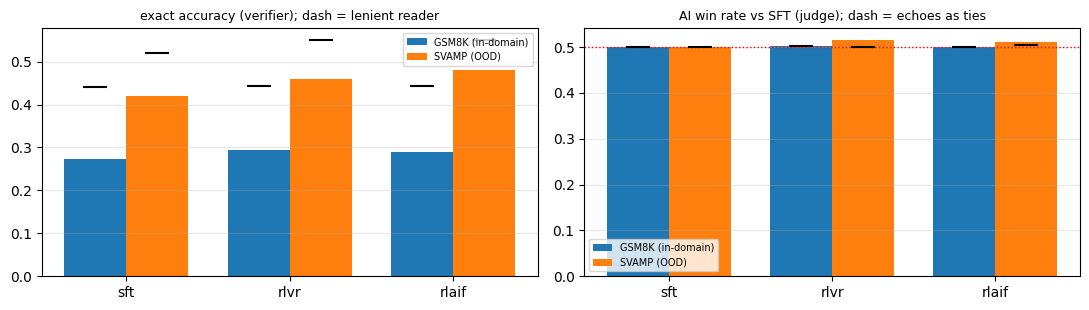

In [12]:
# T12. Combine everything (compare_feedback): main table, diagnostic table, feedback-source numbers.
#      Official columns first; lenient_accuracy and the *_echo_as_tie columns are the supplementary versions next to them.
run('python -m task5_feedback.probe --config configs/feedback.yaml --only lenient')
LA = pd.read_csv(f'{RES}/probe/lenient_accuracy.csv')
expect('how much of exact accuracy is FORMAT? (RQ3, verifier specification)', 'lenient reader also accepts #### $N / #### Answer: N / \\boxed{N} / "the answer is N" (supplementary only; the verifier stays official)',
       {f'{r.dataset}/{r.policy}': f'{r.exact_accuracy:.3f} -> {r.lenient_accuracy:.3f}' for r in LA.itertuples()}, None)
display(LA.round(3))
run('python -m task5_feedback.compare_feedback --config configs/feedback.yaml')
SUM = load_json(f'{RES}/task5_summary.json')
T = pd.read_csv(f'{RES}/task5_main_table.csv')
show = [c for c in ['dataset', 'policy', 'accuracy', 'lenient_accuracy', 'format_compliance', 'win_rate_vs_sft', 'win_rate_vs_sft_echo_as_tie', 'judge_echoes_vs_sft',
                    'len_mean', 'len_std', 'at_cap_rate'] if c in T.columns]
display(T[show].round(3))
display(pd.read_csv(f'{RES}/task5_diagnostic_table.csv').round(3))
FS = SUM['feedback_source']
expect('feedback-source discussion numbers', 'coverage, noise, exploitability, inference cost (official, plus echo-as-tie versions)',
       {k: (round(v, 6) if isinstance(v, float) else v) for k, v in FS.items() if not isinstance(v, dict)}, None)
print('    coverage / picks-correct, official    :', FS.get('coverage_judge_separates_verifier_ties_gsm'), FS.get('judge_picks_correct_when_verifier_decisive_gsm'))
print('    coverage / picks-correct, echo-as-tie :', FS.get('coverage_judge_separates_verifier_ties_gsm_echo_as_tie'), FS.get('judge_picks_correct_when_verifier_decisive_gsm_echo_as_tie'))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
x = np.arange(len(POL)); w = 0.38
for ax, col, extra, title in [(axes[0], 'accuracy', 'lenient_accuracy', 'exact accuracy (verifier); dash = lenient reader'),
                              (axes[1], 'win_rate_vs_sft', 'win_rate_vs_sft_echo_as_tie', 'AI win rate vs SFT (judge); dash = echoes as ties')]:
    for i, d in enumerate(['gsm', 'transfer']):
        sub = T[T.dataset == d].set_index('policy').loc[POL]
        ax.bar(x + (i - .5) * w, sub[col], w, label={'gsm': 'GSM8K (in-domain)', 'transfer': 'SVAMP (OOD)'}[d])
        if extra in sub.columns:
            ax.scatter(x + (i - .5) * w, sub[extra], marker='_', s=300, color='k', zorder=3)
    ax.set_xticks(x); ax.set_xticklabels(POL); ax.set_title(title, fontsize=9); ax.legend(fontsize=7); ax.grid(alpha=.3, axis='y')
axes[1].axhline(0.5, color='r', ls=':', lw=1)
fig.tight_layout(); fig.savefig(f'{FIG}/accuracy_winrate.png', dpi=140); plt.show(); plt.close(fig)

## Part H - qualitative evidence

In [13]:
# T13. Qualitative evidence (required): reasoning-only corruption, persuasive filler, gold distractor, wrong final;
#      judge echoes shown verbatim; GSM8K cases where verifier and judge disagree (echoes excluded - they are not
#      preferences). The notebook finds them; the interpretation is yours.
from task5_feedback.score_perturbations import load_diagnostic_groups, response_of, problem_of, gold_of
D = load_diagnostic_groups(cfg['paths']['task5_diagnostics'])
AR = read_jsonl(f'{RES}/probe/judge_raw.jsonl')
HR = {(str(r['problem_id']), r['pair']): r for r in AR if r['role'] == 'headline'}
DP = read_jsonl(f'{RES}/diagnostics/pairs.jsonl')
is_real = lambda p: HR.get((str(p['problem_id']), p['pair']), {}).get('cls') != 'ECHO'
for ptype, want in [('reasoning', None), ('filler', 'WRONG'), ('distractor', None), ('outcome', None)]:
    cand = ([p for p in DP if p['pair'] == ptype and is_real(p) and (want is None or p.get('judge') == want)]
            or [p for p in DP if p['pair'] == ptype and is_real(p)] or [p for p in DP if p['pair'] == ptype])
    p = cand[0]; V = D[str(p['problem_id'])]; h = HR.get((str(p['problem_id']), ptype), {})
    print(f'\n######## {ptype}: problem {p["problem_id"]} | verifier {p["verifier"]} | judge {p.get("judge")} '
          f'(the judge wrote {h.get("raw", "?")!r}; reversed order: {p.get("judge_reversed_raw")})')
    print('  PROBLEM  :', clip(problem_of(V['clean_correct']), 200), '| gold', gold_of(V['clean_correct']))
    print('  CLEAN    :', clip(response_of(V['clean_correct']), 300))
    print('  PERTURBED:', clip(response_of(V[p['variant']]), 300))
def names_of(r):
    if r['role'] == 'headline': return ('clean', f"{r['pair']} variant")
    if r['role'] == 'reversed': return (f"{r['pair']} variant", 'clean')
    if r['role'] == 'group':    return tuple(r['pair'].split('|'))
    return tuple(r['pair'].split('_vs_'))
E = [r for r in AR if r['cls'] == 'ECHO']
print(f'\n######## judge echoes: {len(E)} of {len(AR)} audited comparisons (one example per source)')
for src in ['diagnostic', 'gsm', 'transfer']:
    e = next((r for r in E if r['source'] == src), None)
    if e is None: continue
    a, b = names_of(e); first = b if e['swap'] else a
    won = {'A': a, 'B': b, 'TIE': 'nobody (TIE)'}[e['result']]
    print(f"  {src} / {e['role']} ({a} vs {b}), problem {e.get('problem_id', e.get('id'))}: the judge wrote {e['raw']!r} -> the parser read 'A' = "
          f"shown first = {first} -> official verdict: {won} wins | echo-as-tie: TIE")
EP = {(r['pair'], str(r['id'])) for r in AR if r['source'] == 'gsm' and r['role'] == 'policy' and r['cls'] == 'ECHO'}
P = read_jsonl(f'{RES}/gsm/pairs.jsonl'); G = {q: {r['id']: r for r in read_jsonl(f'{RES}/gsm/generations_{q}.jsonl')} for q in POL}
echo_pair = lambda r: (f"{r['x']}_vs_{r['y']}", str(r['id'])) in EP
bad_all = [r for r in P if r['verifier_diff'] != 0 and np.sign(r['verifier_diff']) != np.sign(r['x_score'] - 0.5) and r['judge'] != 'TIE']
bad = [r for r in bad_all if not echo_pair(r)]
print(f'\n######## GSM8K: the judge preferred the WRONG-answer response over the correct one in {len(bad)} decisive pairs '
      f'(+{len(bad_all) - len(bad)} more that were echoes, not preferences)')
for r in bad[:2]:
    x, y = G[r['x']][r['id']], G[r['y']][r['id']]
    print(f'\n--- {r["id"]} | {r["x"]} (correct {x["correct"]}, {x["response_tokens"]} tok) vs {r["y"]} (correct {y["correct"]}, {y["response_tokens"]} tok) | judge prefers {r["x"] if r["x_score"] == 1 else r["y"]}')
    print('  PROBLEM:', clip(x['problem'], 180), '| gold', x['gold'])
    print(f'  {r["x"]:6s}:', clip(x['response'], 260)); print(f'  {r["y"]:6s}:', clip(y['response'], 260))
dec = [r for r in P if r['judge'] != 'TIE' and not r['identical'] and not echo_pair(r)]
lp = {}
for r in dec:
    lp.setdefault(f"{r['x']}_vs_{r['y']}", []).append((r['x_tokens'] > r['y_tokens']) == (r['x_score'] == 1))
expect('judge length preference on GSM8K (RQ2)', 'share of REAL decisive verdicts (echoes excluded) that went to the LONGER answer; ~0.5 = no length bias; n is small',
       {k: f'{np.mean(v):.2f} of {len(v)}' for k, v in lp.items()} or 'no real decisive verdicts', None)


######## reasoning: problem 103 | verifier TIE | judge TIE (the judge wrote 'TIE'; reversed order: TIE)
  PROBLEM  : A fog bank rolls in from the ocean to cover a city. It takes 10 minutes to cover every 3 miles of the city. If the city is 42 miles across from the oceanfront to the opposite inland edge, how many min ... | gold 140
  CLEAN    : The city will be covered in 42 / 3 = <<42/3=14>>14 intervals of 10 minutes. Thus, it will take 14 * 10 = <<14*10=140>>140 minutes for the fog to cover the whole city. #### 140
  PERTURBED: The city will be covered in 42 / 3 = <<42/3=15>>14 intervals of 10 minutes. Thus, it will take 14 * 10 = <<14*10=140>>140 minutes for the fog to cover the whole city. #### 140

######## filler: problem 558 | verifier TIE | judge WRONG (the judge wrote 'B'; reversed order: A)
  PROBLEM  : Timothy's locker is 24 cubic inches. Zack's locker is half as big as Timothy's locker. Peter's locker is 1/4 as big as Zack's locker. How big is Peter's locker in cubic inches

## Part I - supplementary: how far did each method move the weights?

In [14]:
# T14. Supplementary: how far did each method move the weights? Relative LoRA update ||(alpha/r) B A||_F / ||W||_F,
#      averaged over the adapted matrices (q_proj, v_proj). The Task 1-3 standard adapters come from the pa2-task4 dataset.
# sha256 of adapter_model.safetensors from YOUR Task 1-3 standard runs (the same fingerprints Task 4 checked)
EXPECTED_SHA = {'dpo':  '633c31e787bd57d2d09401ba5f50e5027ff808819733aee92d5cd8f08d773f73',
                'ppo':  '37bde6d075db8ee601e8f3fbcb1b8626aba829d7b2ed8c99aa0727d19758263d',
                'grpo': '2988393d19c662083e30d1fd33575a6dff40d6973607811d9db2c3bb5b87fa1e'}
ADAPTER_DIRS = {'dpo': 'outputs/task1_dpo/standard', 'ppo': 'outputs/task2_ppo/standard', 'grpo': 'outputs/task3_grpo/standard'}
sha = lambda f: hashlib.sha256(open(f, 'rb').read()).hexdigest() if os.path.exists(f) else 'MISSING'
for name, rel in ADAPTER_DIRS.items():
    hits = [os.path.dirname(p) for b in [BASE, '/tmp/unzipped'] for p in glob.glob(f'{b}/**/{rel}/adapter_config.json', recursive=True)]
    hits = sorted(hits, key=lambda h: sha(f'{h}/adapter_model.safetensors') != EXPECTED_SHA[name])      # a fingerprint match first
    for h in hits: print(f'  {name:5s} found: {h}  [{"standard run" if sha(f"{h}/adapter_model.safetensors") == EXPECTED_SHA[name] else "NOT your standard adapter"}]')
    if hits:
        os.makedirs(rel, exist_ok=True); [shutil.copy(f'{hits[0]}/{f}', f'{rel}/{f}') for f in os.listdir(hits[0]) if os.path.isfile(f'{hits[0]}/{f}')]
got_sha = {n: sha(f'{r}/adapter_model.safetensors') for n, r in ADAPTER_DIRS.items()}
expect('Task 1-3 adapters = your standard runs (sha256 fingerprints)', {n: h[:12] for n, h in EXPECTED_SHA.items()}, {n: h[:12] for n, h in got_sha.items()},
       all(got_sha[n] == EXPECTED_SHA[n] for n in EXPECTED_SHA))
import torch, tempfile
from safetensors.torch import save_file
from task5_feedback.probe import adapter_delta_norms
td = tempfile.mkdtemp(); g = torch.Generator().manual_seed(0)
A_, B_, W_ = torch.randn(8, 64, generator=g), torch.randn(32, 8, generator=g), torch.randn(32, 64, generator=g)
save_file({'base_model.model.model.layers.0.self_attn.q_proj.lora_A.weight': A_, 'base_model.model.model.layers.0.self_attn.q_proj.lora_B.weight': B_}, f'{td}/adapter_model.safetensors')
json.dump({'lora_alpha': 16, 'r': 8}, open(f'{td}/adapter_config.json', 'w'))
got = adapter_delta_norms(td, {'model.layers.0.self_attn.q_proj.weight': W_})['rel_mean']; want = float((2 * B_ @ A_).norm() / W_.norm())
expect('adapter-size formula on synthetic tensors', f'||(alpha/r) B A|| / ||W|| = {want:.4f}', f'{got:.4f}', abs(got - want) < 1e-5)
run('python -m task5_feedback.probe --config configs/feedback.yaml --only adapters')
AN = pd.read_csv(f'{RES}/probe/adapter_norms.csv'); display(AN.round(5))
expect('how far each adapter moved the weights (relative LoRA update, mean over adapted matrices)', 'one scale for all post-training in this assignment',
       {r.adapter: f'{r.rel_mean:.2e} (max {r.rel_max:.2e}, {r.base_matched}/{r.modules} matched)' for r in AN.itertuples()}, None)

  dpo   found: /kaggle/input/notebooks/zylah628/task1-kaggle-run1/outputs/outputs/task1_dpo/standard  [standard run]
  dpo   found: /kaggle/input/datasets/zylah628/outputstask1-dpostandard/outputs/task1_dpo/standard  [standard run]
  dpo   found: /tmp/unzipped/task1_adapters/outputs/task1_dpo/standard  [standard run]
  ppo   found: /kaggle/input/notebooks/zylah628/task2-kaggle-run3/outputs/outputs/task2_ppo/standard  [standard run]
  ppo   found: /kaggle/input/datasets/zylah628/outputstask2-ppostandard/outputs/task2_ppo/standard  [standard run]
  ppo   found: /tmp/unzipped/task2_adapters/outputs/task2_ppo/standard  [standard run]
  grpo  found: /kaggle/input/notebooks/zylah628/task3-kaggle-run1/outputs/outputs/task3_grpo/standard  [standard run]
  grpo  found: /kaggle/input/datasets/zylah628/outputstask3-grpostandard/outputs/task3_grpo/standard  [standard run]
  grpo  found: /tmp/unzipped/task3_adapters/outputs/task3_grpo/standard  [standard run]
[PASS   ] Task 1-3 adapters = your stan

,adapter,path,modules,scale_alpha_over_r,abs_mean,rel_mean,rel_max,base_matched
0,dpo,outputs/task1_dpo/standard,56,2.0,0.02227,0.00075,0.00126,56
1,ppo,outputs/task2_ppo/standard,56,2.0,0.00366,0.00012,0.00018,56
2,grpo,outputs/task3_grpo/standard,56,2.0,0.00318,0.00010,0.00016,56
3,ppo_midpoint,checkpoints/ppo_midpoint_policy,56,2.0,0.00266,0.00009,0.00013,56
4,grpo_midpoint,checkpoints/grpo_midpoint_policy,56,2.0,0.00235,0.00008,0.00012,56
5,rlvr,checkpoints/rlvr_policy,56,2.0,0.00293,0.00010,0.00017,56
6,rlaif,checkpoints/rlaif_policy,56,2.0,0.00225,0.00007,0.00011,56


[OBSERVE] how far each adapter moved the weights (relative LoRA update, mean over adapted matrices)
            expected: one scale for all post-training in this assignment
            actual  : {'dpo': '7.49e-04 (max 1.26e-03, 56/56 matched)', 'ppo': '1.18e-04 (max 1.76e-04, 56/56 matched)', 'grpo': '1.04e-04 (max 1.57e-04, 56/56 matched)', 'ppo_midpoint': '8.61e-05 (max 1.30e-04, 56/56 matched)', 'grpo_midpoint': '7.64e-05 (max 1.17e-04, 56/56 matched)', 'rlvr': '9.56e-05 (max 1.68e-04, 56/56 matched)', 'rlaif': '7.30e-05 (max 1.09e-04, 56/56 matched)'}


## Part S - save

In [15]:
# T15. Save everything. Run this even if a cell above failed.
zip_dir(f'{OUT}/results/task5_feedback', 'results/task5_feedback', f'{OUT}/task5_results.zip')
for f in sorted(os.listdir(OUT)):
    if os.path.isfile(f'{OUT}/{f}'): print(f'{os.path.getsize(f"{OUT}/{f}") / 1e6:8.2f} MB  {f}')
tally = Counter(t for t, _ in CHECKS)
print(f'\nChecks: {tally.get("PASS", 0)} PASS | {tally.get("FAIL", 0)} FAIL | {tally.get("OBSERVE", 0)} OBSERVE')
for t, n in CHECKS:
    if t == 'FAIL': print('   FAIL:', n)
print('\ntask5_results.zip -> unzip at your repo root and COMMIT (generations, pairs, judge cache, raw judge outputs, metrics, figures)')

    0.52 MB  task5_results.zip

Checks: 34 PASS | 0 FAIL | 24 OBSERVE

task5_results.zip -> unzip at your repo root and COMMIT (generations, pairs, judge cache, raw judge outputs, metrics, figures)


## Notes
- **A FAIL in T1-T7 means stop** and send the output to Claude. A FAIL in T11 (fidelity or rebuild) means the audit did not reproduce the official verdicts - send it too.
- **Official vs supplementary.** Official = what the supplied verifier and judge produce (T8-T10, and the plain columns of the T12 tables). Supplementary, always shown next to the official number and never instead of it: `*_echo_as_tie` (judge echoes counted as no verdict), `lenient_accuracy` (format-tolerant answer reader), adapter sizes.
- **Echo** = a judge output that names more than one option (e.g. `A, B` or `A,B,TIE`: the option list repeated and cut off by the 4-token cap). The supplied parser takes the first match, `A` = "the answer shown first wins", so an echo becomes a coin flip set by the A/B swap. Echo-as-tie scores it 0.5, like a tie. This is a judge-parser specification issue, the counterpart of the verifier's `#### $300` issue.
- **Decisions to state in the report:** greedy decoding, 512-token cap, batch 16 for all policies; the judge sees the plain problem text (no format instruction); win = 1 / tie = 0.5 / loss = 0, with word-for-word identical answers scored as a tie without a judge call (count reported); the supplied judge's hash-based A/B position balancing and cache used unchanged; the diagnostic headline verdict is the supplied single call compare(problem, clean, perturbed), and the reversed call is a separate consistency check; S_outcome uses clean vs good-reasoning-wrong-final, the distractor pair is reported separately; win-rate uncertainty = 1.96 standard errors; accuracy CIs = Wilson; paired accuracy tests = exact McNemar; ambiguous judge outputs reported separately (echo-as-tie).
- **Do not put the 0/1 verifier reward and the [0, 1] win rate on one axis as if they were the same utility.**
- **The pipeline is the scripts** (`python -m task5_feedback.*`); this notebook only runs and checks them.